# WKM with forward sensing


$$v_+(i)=v_+\exp\left(\sum_{k=2}^{R}\beta_k n(r_i+k e_i)\right)$$

In [10]:
import numpy as np
import torch
import matplotlib.pyplot as plt
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu': torch.set_num_threads(1)
torch.manual_seed(7)
print(f'PyTorch {torch.__version__} | device: {device}')


PyTorch 2.7.1+cu126 | device: cuda:1


In [11]:
try:
    from numba import njit
except ImportError:
    njit = lambda f: f

@njit
def local_forward_rate(occupied, old, direction, L, weights, R, mode, base):
    dr = np.array([-1, 0, 1, 0])
    dc = np.array([0, 1, 0, -1])
    row, col = old // L, old % L
    exponent = 0.0
    if mode == 0:
        for k in range(2, R + 1):
            rr, cc = (row + k*dr[direction]) % L, (col + k*dc[direction]) % L
            exponent += weights[k-2] * (occupied[rr*L+cc] != 0)
    else:
        for k in range(2, R + 1):
            count = 0
            for dy in range(-k, k+1):
                for dx in range(-k, k+1):
                    if max(abs(dy), abs(dx)) == k:
                        rr, cc = (row+dy) % L, (col+dx) % L
                        count += occupied[rr*L+cc] != 0
            exponent += weights[k-2] * count / (8.0*k)
    return base * np.exp(exponent)

@njit
def sensing_events(occupied, positions, directions, rates, weights, R, mode, L,
                   burn_events, total_events, sample_interval, seed):
    np.random.seed(seed)
    N = len(positions)
    base, lateral, backward, rotation = rates
    max_forward = base * np.exp(np.maximum(weights, 0.0).sum())
    props = np.array([max_forward, lateral, lateral, backward, rotation, rotation])
    prop_total = props.sum()
    offsets = np.array([0, 1, 3, 2])
    fsum, f2sum, ns = 0.0, 0.0, 0
    elapsed_time = 0.0
    dr = np.array([-1, 0, 1, 0])
    dc = np.array([0, 1, 0, -1])
    for event in range(total_events):
        elapsed_time -= np.log(max(np.random.random(), 1e-12))/(N*prop_total)
        p = np.random.randint(N)
        r = np.random.random()*prop_total
        kind = 0
        while r >= props[kind]:
            r -= props[kind]
            kind += 1
        if kind < 4:
            direction = (directions[p] + offsets[kind]) % 4
            old = positions[p]
            y, x = old//L, old%L
            new = ((y+dr[direction])%L)*L + (x+dc[direction])%L
            accepted = True
            if kind == 0:
                rate = local_forward_rate(occupied, old, direction, L, weights, R, mode, base)
                accepted = np.random.random() < rate/max_forward
            if accepted and occupied[new] == 0:
                occupied[old] = 0
                occupied[new] = p+1
                positions[p] = new
        else:
            directions[p] = (directions[p] + (1 if kind == 4 else 3)) % 4
        if event >= burn_events and (event-burn_events)%sample_interval == 0:
            jam = 0
            for y in range(L):
                for x in range(L):
                    q = y*L+x
                    if (occupied[q] != 0 and occupied[y*L+(x+1)%L] != 0 and
                        occupied[y*L+(x-1+L)%L] != 0 and
                        occupied[((y+1)%L)*L+x] != 0 and
                        occupied[((y-1+L)%L)*L+x] != 0):
                        jam += 1
            f = jam/N
            fsum += f
            f2sum += f*f
            ns += 1
    mean = fsum/ns
    return mean, max(f2sum/ns-mean*mean, 0.0), elapsed_time

def wkm_sensing(L, phi, v_plus, weights, lateral=1.0, v_minus=1.0, Drot=0.1,
                burn_sweeps=500, sample_sweeps=1000, sample_every=10, seed=0):
    weights = np.asarray(weights, dtype=np.float64)
    R = len(weights)+1
    assert L > 1 and 0 < phi < 1 and sample_sweeps >= sample_every
    assert v_plus > 0 and v_minus > 0 and lateral >= 0 and Drot >= 0
    assert 2*R < L, 'Require 2*R < L to avoid periodic duplicate sensing.'
    rng = np.random.default_rng(seed)
    N = round(phi*L*L)
    positions = rng.permutation(L*L)[:N].astype(np.int32)
    directions = rng.integers(0, 4, N, dtype=np.int32)
    occupied = np.zeros(L*L, dtype=np.int32)
    occupied[positions] = np.arange(1, N+1)
    rates = np.array([v_plus, lateral, v_minus, Drot], dtype=np.float64)
    mean, var, t = sensing_events(
        occupied, positions, directions, rates, weights, R, 0, L,
        N*burn_sweeps, N*(burn_sweeps+sample_sweeps), N*sample_every, seed)
    return torch.from_numpy((occupied.reshape(L,L) != 0)).to(device), mean, var, t


In [20]:
R = 5
shell_weights = np.array([0, 0, 0, 2])  # beta_2, ..., beta_R
L = 100
densities = np.linspace(.1, .5, 9)
v_plus_grid = np.arange(1., 26., 2.)
Drot, v_minus, v0 = .1, 1., 1.
means = np.empty((len(v_plus_grid), len(densities)))
variances = np.empty_like(means)
for i, v_plus in enumerate(v_plus_grid):
    for j, phi in enumerate(densities):
        _, means[i, j], variances[i, j], _ = wkm_sensing(
            L, phi, v_plus, shell_weights, lateral=v0, v_minus=v_minus,
            Drot=Drot, burn_sweeps=500, sample_sweeps=1000,
            sample_every=10, seed=100*i+j)
log_variances = np.log(np.maximum(variances, 1e-12))

size_density = .15
sizes = (16, 32, 64, 128, 256, 512)
size_v_plus = np.arange(5., 26., 2.)
size_variances = np.empty((len(sizes), len(size_v_plus), 3))
for i, size in enumerate(sizes):
    for j, v_plus in enumerate(size_v_plus):
        for run in range(3):
            _, _, size_variances[i, j, run], _ = wkm_sensing(
                size, size_density, v_plus, shell_weights, lateral=v0,
                v_minus=v_minus, Drot=Drot, burn_sweeps=500,
                sample_sweeps=1000, sample_every=10,
                seed=10000*i+100*j+run)
size_log_variances = np.log(np.maximum(size_variances.mean(2), 1e-12))
size_log_errors = size_variances.std(2, ddof=1) / (
    np.sqrt(3)*np.maximum(size_variances.mean(2), 1e-12))
print('WKM sensing phase maps and size scan completed')


WKM sensing phase maps and size scan completed


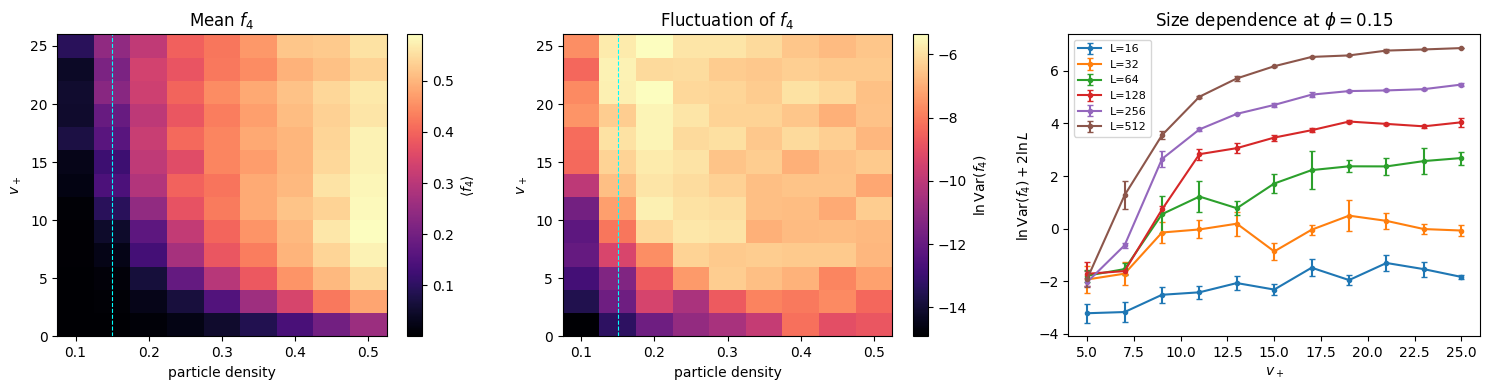

In [21]:
sigma = v_plus_grid + v_minus + 2*v0 + 2*Drot
kappa = (1-(1-2*Drot/sigma)**(2*sigma/Drot))/4
pe = (v_plus_grid-v_minus)/(2*Drot)
phase_fraction = (pe[:, None]*kappa[:, None]-1/densities[None, :]) / (
    pe[:, None]*kappa[:, None]-1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, data, title, label in zip(ax[:2], [means, log_variances],
                                  [r'Mean $f_4$', r'Fluctuation of $f_4$'],
                                  [r'$\langle f_4\rangle$', r'$\ln\operatorname{Var}(f_4)$']):
    im = a.pcolormesh(densities, v_plus_grid, data, shading='nearest', cmap='magma')
    a.axvline(size_density, color='cyan', ls='--', lw=.8)
    a.set(xlabel='particle density', ylabel=r'$v_+$', title=title)
    fig.colorbar(im, ax=a, label=label)
for i, size in enumerate(sizes):
    ax[2].errorbar(size_v_plus, size_log_variances[i] + 2*np.log(size),
                   yerr=size_log_errors[i], marker='o', ms=3,
                   capsize=2, label=f'L={size}')
ax[2].set(xlabel=r'$v_+$', ylabel=r'$\ln\operatorname{Var}(f_4) + 2 \ln L$',
          title=fr'Size dependence at $\phi={size_density}$')
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
